# Letting the images choose a threshold

Every rejection rule in this pipeline is a judgement about a particle you cannot see. This
notebook is about the one case where you *can* see it, and what changes when you look.

**The situation.** UIOOPS rejects a particle whose shadow looks hollow -- a ring rather than a
blob -- on the reasoning that a hollow shadow is usually an out-of-focus droplet rather than a
real particle of that size. That rule is applied at every size, and nothing in the code knows
whether it is right for *your* instrument or *your* cloud.

**What this notebook does.** Builds a synthetic population where the answer is known by
construction, runs the rejection three ways, and compares the size distributions:

1. **stock** -- the hollow test on, at every size, as UIOOPS ships it;
2. **hollow test off** -- the `stock-v3.5-image-assisted` profile;
3. **a size threshold** -- the hollow test on below a size, bypassed above it.

The third is not a compromise between the first two. It exists because when the particles were
actually looked at, *the rule turned out to be right at small sizes and wrong at large ones* --
and no amount of reasoning about the code could have produced that.

> **Nothing here needs campaign data.** The flight is invented in cell 2 and thrown away at the
> end. The numbers you see are computed from it when you run this, not typed into the text.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page). **Related:** [12_particle_gallery](12_particle_gallery.ipynb). **Needs:** `pip install "arrayprobe[extra]"` (matplotlib).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )


Import the hollow-size rule and the two rejection settings, register the image-assisted profile, and print the hollow-test setting each one carries. This shows the difference between the two profiles before any particles are processed.

In [2]:
import numpy as np

from arrayprobe.profiles import PROFILES, register_stock_v35_image_assisted
from arrayprobe_uiops import hollow_size_rule as hsr
from arrayprobe_uiops.measure import (
    IMAGE_ASSISTED_V35_REJECT_CONFIG,
    STOCK_V35_REJECT_CONFIG,
)

register_stock_v35_image_assisted()

print("stock hollow test:         rej_hollow =", STOCK_V35_REJECT_CONFIG.rej_hollow)
print("image-assisted profile:    rej_hollow =", IMAGE_ASSISTED_V35_REJECT_CONFIG.rej_hollow)
print("profile is registered as: ", PROFILES["stock-v3.5-image-assisted"].name)

stock hollow test:         rej_hollow = True
image-assisted profile:    rej_hollow = False
profile is registered as:  stock-v3.5-image-assisted


## Where the labels come from: the triage server

The threshold below is chosen from particle images a person labelled in the triage server
(`arrayprobe triage --decoded-dir <folder>`). Two screens do the work. The flight page shows a
flight's particles as a contact sheet, largest first, with accepted, rejected and all views:

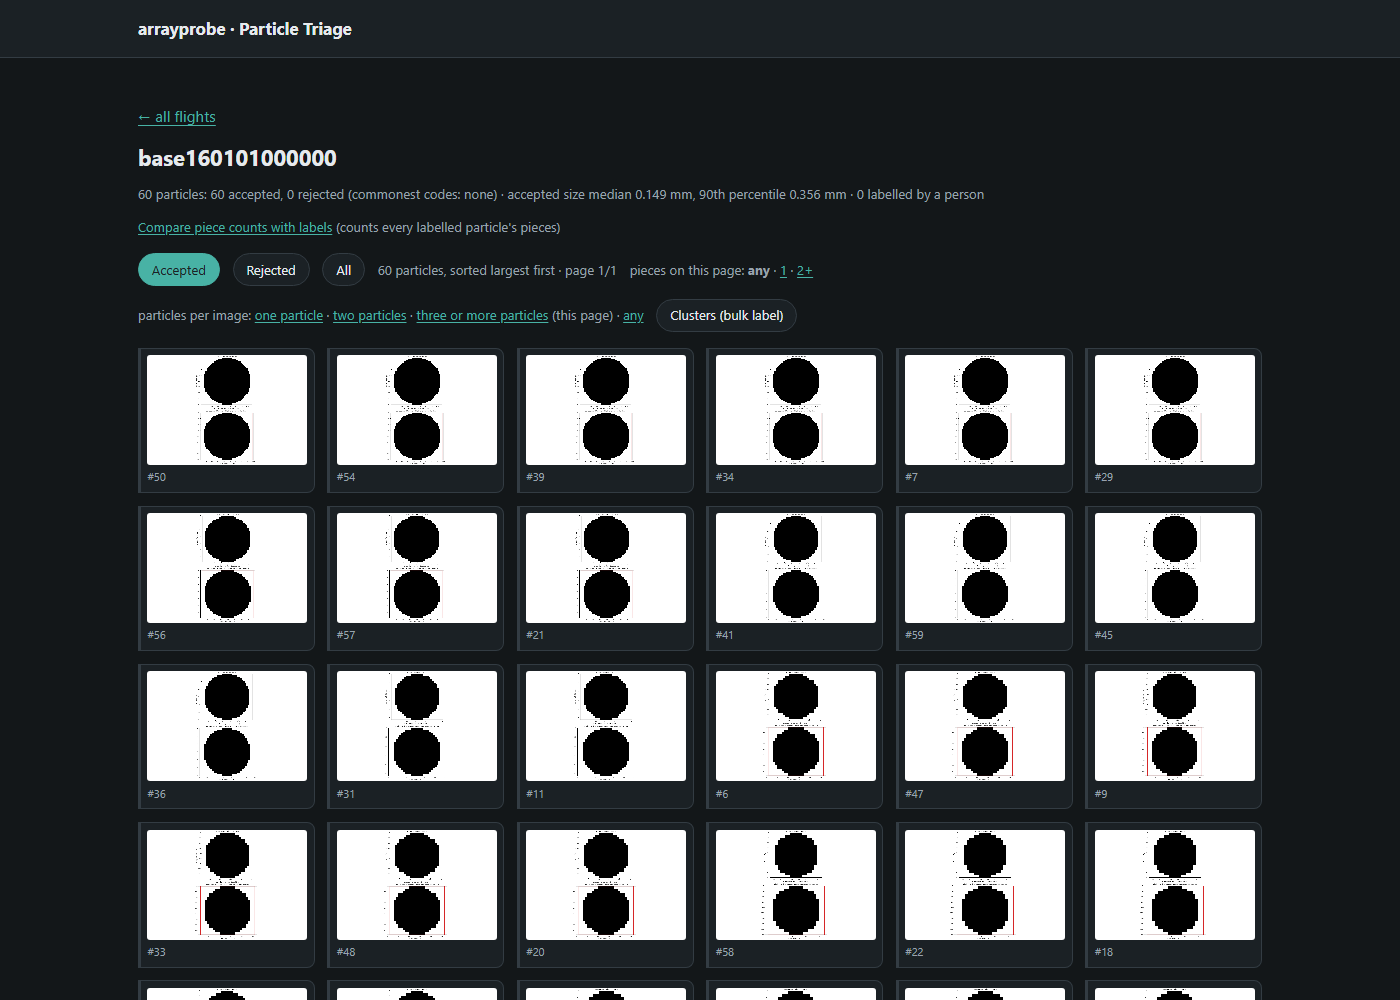

Clicking a particle opens its labelling page: the image, the fields the processing wrote for it,
and four verdicts (artifact, real, two particles, unsure), each on a key. A verdict is saved at
once, with who made it, when and from which queue, to `triage_verdicts/<flight>.json` beside the
decoded files; the processing output is never touched. Here, one hollow particle from the synthetic demo flight
(particle 2 of `base160101000000`):

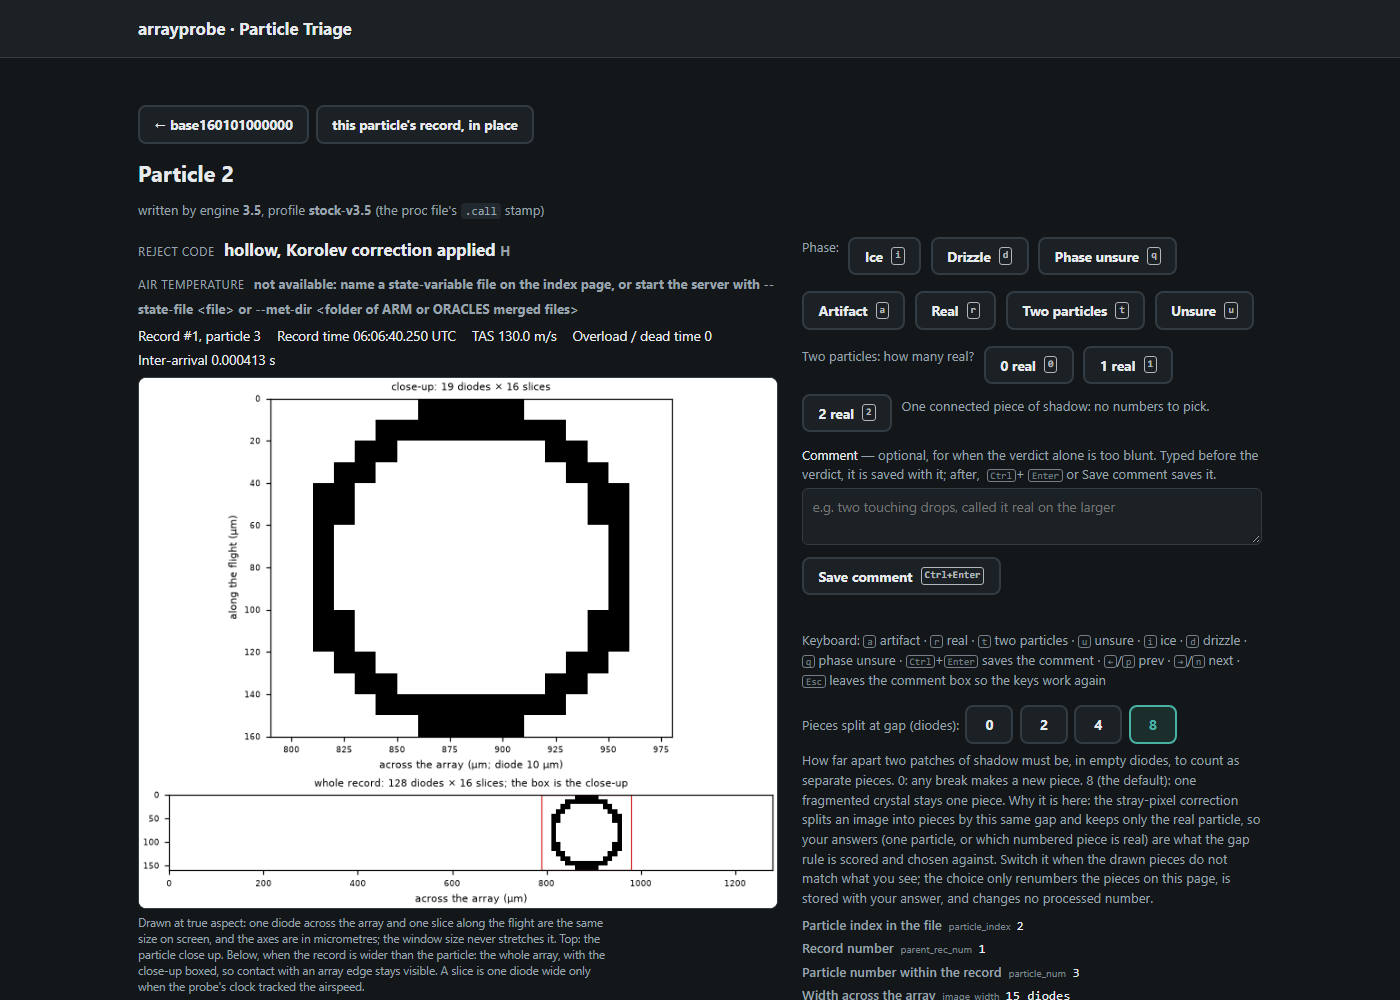

Screenshots from the synthetic demo flight `base160101000000`. To measure how
consistent the labels are, `arrayprobe triage-recheck` re-shows a sample blind and
`arrayprobe triage-agreement` reports Cohen's kappa.


## 1. The evidence that produced the threshold

The size threshold below is not a tuned parameter. It comes from particle images labelled by eye
(480 labels across sixteen cells, in two rounds; the five bars below plot the 165 of them that
are particles stock rejected as hollow, the other 315 being controls and wide-band labels). For each size bin, the question asked of every
image was: *stock rejects this as hollow -- is it actually a real particle?*

The table is read from the code that carries it, so it cannot drift from the rule it justifies.

In [3]:
rule = hsr.HollowSizeRule(enabled=True, threshold_um=155.0)
print(f"rule: hollow test applies BELOW {rule.threshold_um:.0f} µm, bypassed at or above\n")

# The labelled evidence, from the module's own docstring table (the 165 stock-reject labels of the 480).
evidence = [(55, 105, 0.00, 25), (105, 155, 0.45, 40), (155, 205, 0.60, 40),
            (205, 255, 0.63, 30), (255, 305, 0.87, 30)]
print(f"{'size bin':>14}  {'wrongly rejected':>17}  {'n':>4}   hollow test")
for lo, hi, frac, n in evidence:
    applies = hsr.hollow_test_applies(rule, (lo + hi) / 2)
    print(f"{lo:>6}-{hi:<7}  {frac:>16.0%}  {n:>4}   {'ON (stock)' if applies else 'bypassed'}")

rule: hollow test applies BELOW 155 µm, bypassed at or above

      size bin   wrongly rejected     n   hollow test
    55-105                    0%    25   ON (stock)
   105-155                   45%    40   ON (stock)
   155-205                   60%    40   bypassed
   205-255                   63%    30   bypassed
   255-305                   87%    30   bypassed


Read the first column downwards. At 55--105 µm the hollow test was **right every time** --
none of the 25 particles it rejected was real. By 255--305 µm it was **wrong 87% of the time**.

That is why "turn the hollow test off" is not the answer, and neither is "leave it on". The
rule is correct in one size range and incorrect in another, and the crossing point is what the
threshold encodes. It sits at 155 µm because that is where the labelled fraction crosses a
half, not because 155 is a round number.

**The honest caveat, and it matters more than the number:** these are one person's labels on one
instrument's data. The method is what transfers -- look at your own images, in your own size
bins, and let them place your own threshold. The 155 µm is an example of the answer, not the
answer.

## 1b. The same evidence as a picture

The table above is the whole argument, and a table hides its own shape. Plotted,
the point is unmissable: the hollow test's error rate is not flat, it climbs with
size, and 155 um is where it stops being a rejection anyone would defend.


blue: below 155 µm the rule keeps the hollow test; red: from 155 µm up, where most rejects were real, it skips it


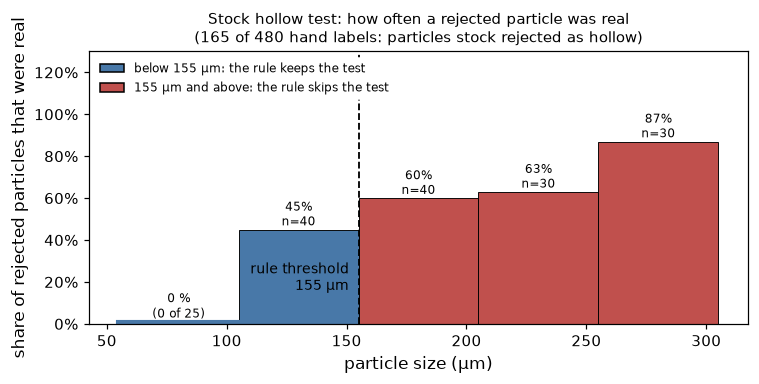

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

FIG_DIR = Path("examples/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
PNG_META = {"Software": None}  # no version stamp, so a re-run rewrites identical bytes

lo, hi, frac, n = (list(c) for c in zip(*evidence))
mid = [(a + b) / 2 for a, b in zip(lo, hi)]
fig, ax = plt.subplots(figsize=(7.0, 3.6))
bars = ax.bar(mid, frac, width=[b - a for a, b in zip(lo, hi)],
              edgecolor="black", linewidth=0.6,
              color=["#4878A8" if m < rule.threshold_um else "#C0504D" for m in mid])
ax.axvline(rule.threshold_um, color="black", linestyle="--", linewidth=1.2)
ax.annotate(f"rule threshold\n{rule.threshold_um:.0f} µm", xy=(rule.threshold_um, 0.3),
            xytext=(rule.threshold_um - 4, 0.3), va="top", ha="right", fontsize=9)
for b, f, count in zip(bars, frac, n):
    x = b.get_x() + b.get_width() / 2
    if f == 0:  # a zero bar is invisible: draw a stub and say what it is
        ax.plot([b.get_x(), b.get_x() + b.get_width()], [0.004] * 2, color="#4878A8", lw=4)
        ax.text(x, 0.03, f"0 %\n(0 of {count})", ha="center", fontsize=8)
    else:
        ax.text(x, f + 0.02, f"{f:.0%}\nn={count}", ha="center", fontsize=8)
ax.set_xlabel("particle size (µm)")
ax.set_ylabel("share of rejected particles that were real")
ax.set_ylim(0, 1.3)
ax.set_title("Stock hollow test: how often a rejected particle was real\n"
             "(165 of 480 hand labels: particles stock rejected as hollow)", fontsize=10)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(handles=[Patch(facecolor="#4878A8", edgecolor="black", label="below 155 µm: the rule keeps the test"),
                   Patch(facecolor="#C0504D", edgecolor="black", label="155 µm and above: the rule skips the test")],
          loc="upper left", fontsize=8, framealpha=1, edgecolor="white")
fig.tight_layout()
fig.savefig(FIG_DIR / "11_hollow_test_error_by_size.png", dpi=120, metadata=PNG_META)
plt.show()
print("blue: below 155 µm the rule keeps the hollow test; red: from 155 µm up, where most rejects were real, it skips it")


*Figure 1. Share of the particles stock rejected as hollow that a person labelled real, per size bin (165 hand labels). Blue bins fall below the 155 µm threshold (dashed), where the rule keeps the hollow test; red bins are at or above it, where the rule skips the test.*

## 1c. Four particles either side of the threshold

**A ring at 80 µm is rejected under both settings and should be; a ring at 160 µm is rejected by
stock and kept by the rule, and the labels say it is usually real.** The four images below are
synthetic rings of the kind the hollow test fires on, drawn on a 10 µm diode grid. For each, the
cell computes what the threshold reads -- the hollow verdict from the package's own
`is_it_hollow` and the particle's size measured across the image -- then which side of the
threshold it falls, what stock and the size rule each do with it, and the labelled fraction of
real particles in its size bin from section 1.

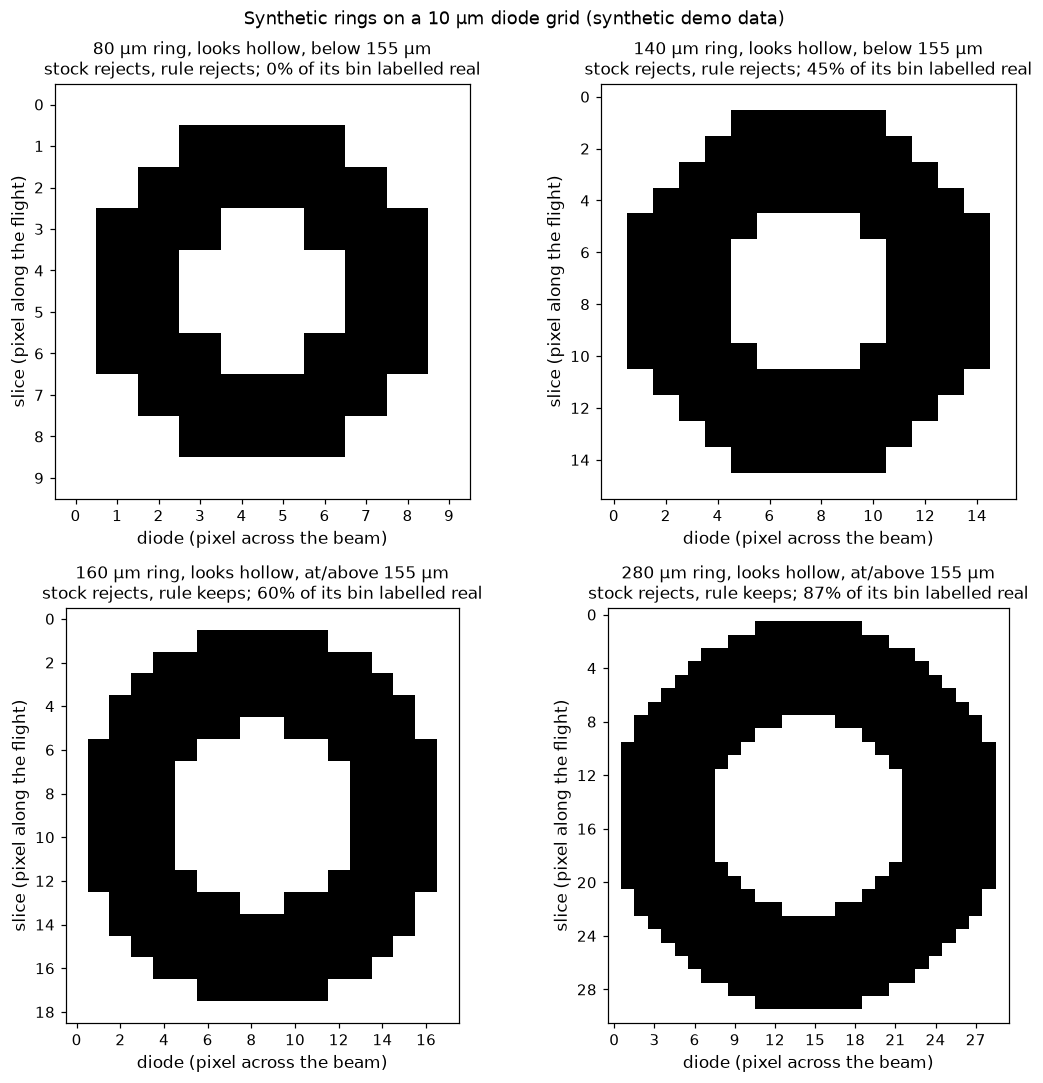

In [5]:
from matplotlib.ticker import MaxNLocator

from arrayprobe_uiops.reject import is_it_hollow

DIODE_UM = 10.0  # synthetic probe pixel size


def ring_image(d_um, hole_frac=0.5, n_diodes=64):
    """Shadow (True = shaded) of a disk of diameter d_um with a centred hole."""
    r = d_um / DIODE_UM / 2
    rows = int(np.ceil(2 * r)) + 4
    y, x = np.mgrid[:rows, :n_diodes]
    rr = np.hypot(y - rows / 2 + 0.5, x - n_diodes / 2 + 0.5)
    return (rr < r) & (rr >= r * hole_frac)


def labelled_real_fraction(size):
    for lo_, hi_, frac_, n_ in evidence:
        if lo_ <= size < hi_:
            return frac_, n_
    return None, 0


fig, axes = plt.subplots(2, 2, figsize=(10.0, 10.0))  # a few large panels per row, enlarged so pixels show
for ax, d_um in zip(axes.ravel(), (80, 140, 170, 290)):
    img = ring_image(d_um)
    ihollow_img = int(is_it_hollow(img, img.shape[0])[0])
    cols = np.where(img.any(axis=0))[0]
    size_img = (cols[-1] - cols[0] + 1) * DIODE_UM   # extent across the diodes
    stock_says = hsr.resolve_ihollow(ihollow_img, size_img, None)
    rule_says = hsr.resolve_ihollow(ihollow_img, size_img, rule)
    side = "below" if size_img < rule.threshold_um else "at/above"
    frac_, n_ = labelled_real_fraction(size_img)
    rws = np.where(img.any(axis=1))[0]
    crop = img[rws[0] - 1:rws[-1] + 2, cols[0] - 1:cols[-1] + 2]  # cropped to the particle
    ax.imshow(crop, cmap="gray_r", interpolation="nearest")  # nearest: every diode visible
    ax.set_xlabel("diode (pixel across the beam)")
    ax.set_ylabel("slice (pixel along the flight)")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    looks = "looks hollow" if ihollow_img else "looks solid"
    title = [f"{size_img:.0f} \u00b5m ring, {looks}, {side} {rule.threshold_um:.0f} \u00b5m",
             f"stock {'rejects' if stock_says else 'keeps'}, rule {'rejects' if rule_says else 'keeps'}; "
             f"{frac_:.0%} of its bin labelled real"]
    ax.set_title(chr(10).join(title), fontsize=11)
fig.suptitle("Synthetic rings on a 10 \u00b5m diode grid (synthetic demo data)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "11_rings_either_side_of_threshold.png", dpi=120, metadata=PNG_META)
plt.show()


*Figure 2. Four synthetic rings (synthetic demo data), cropped to the particle so each diode is visible. Each title gives the ring's measured size and side of the 155 µm threshold, what stock and the size rule do with it, and how often particles in its size bin were labelled real.*

**How these cases place the threshold.** The 80 µm ring sits in the bin where none of the
labelled rejections was real, so rejecting it is right and the threshold should not move below
this range. The 140 µm ring is still rejected by the rule although its bin was labelled real
nearly half the time: an image like it, judged real, argues for loosening the threshold, and an
artefact that looks like it argues for keeping it. The 160 µm ring is the first one the rule
keeps, in a bin labelled real more often than not; a clear artefact there would argue for
tightening. At 280 µm the labels leave no doubt and both readings agree that stock's rejection
is wrong. The threshold sits where the cases on either side stop agreeing, which is the
labelled fraction crossing a half.

In [6]:
# A synthetic population where the truth is known by construction.
rng = np.random.default_rng(20260921)
N = 4000

# Sizes spanning the labelled range and beyond.
size_um = rng.uniform(40.0, 360.0, N)

# Who is genuinely hollow? Small particles that LOOK hollow are out-of-focus artefacts
# (the hollow test is right about them); large ones that look hollow are real particles
# with real structure (the hollow test is wrong about them). That size dependence is the
# whole finding, so it is what the synthetic truth encodes -- interpolated from the
# labelled fractions above rather than invented.
lo_edges = np.array([55, 105, 155, 205, 255], dtype=float)
wrong_frac = np.array([0.00, 0.45, 0.60, 0.63, 0.87])
p_real = np.interp(size_um, lo_edges + 25.0, wrong_frac)

looks_hollow = rng.random(N) < 0.35            # what the shadow looks like
is_really_real = rng.random(N) < p_real        # what it actually is, given its size

print(f"{N} particles, {looks_hollow.sum()} of them with a hollow-looking shadow")
print(f"of those, {int((looks_hollow & is_really_real).sum())} are genuinely real particles")

4000 particles, 1423 of them with a hollow-looking shadow
of those, 810 are genuinely real particles


## 2. The three configurations, on the same particles

`resolve_ihollow_array` is the one function the rule acts through. Given what the shadow looks
like (`ihollow`) and how big the particle is, it returns what the reject stage should be told.

It never turns a *not-hollow* verdict into a *hollow* one -- the rule can only narrow what stock
rejects, never widen it. That is a property worth checking rather than trusting, so the cell
below checks it.

In [7]:
ihollow = looks_hollow.astype(int)

told_stock = hsr.resolve_ihollow_array(ihollow, size_um, None)
told_off = np.zeros_like(ihollow)
told_rule = hsr.resolve_ihollow_array(ihollow, size_um, rule)

assert np.array_equal(told_stock, ihollow), "rule=None must be bit-identical to stock"
assert not np.any((told_rule == 1) & (ihollow == 0)), "the rule must never ADD a rejection"
print("checked: rule=None is stock exactly, and the rule only ever narrows\n")

for label, told in (("stock", told_stock), ("hollow test off", told_off), ("size rule", told_rule)):
    rejected = told == 1
    real_lost = int((rejected & is_really_real).sum())
    artefact_caught = int((rejected & ~is_really_real).sum())
    print(f"{label:>16}: rejects {rejected.sum():>4}  "
          f"-- real particles lost {real_lost:>4}, artefacts caught {artefact_caught:>4}")

checked: rule=None is stock exactly, and the rule only ever narrows

           stock: rejects 1423  -- real particles lost  810, artefacts caught  613
 hollow test off: rejects    0  -- real particles lost    0, artefacts caught    0
       size rule: rejects  509  -- real particles lost  126, artefacts caught  383


## 3. What it does to a size distribution

Rejections are not spread evenly across sizes, so the effect on a size distribution is not a
scale factor. Counting what survives, per bin, is the only way to see where the choice acts.

In [8]:
edges = np.arange(55.0, 361.0, 50.0)
centres = (edges[:-1] + edges[1:]) / 2

def kept_per_bin(told):
    return np.histogram(size_um[told == 0], bins=edges)[0]

k_stock, k_off, k_rule = (kept_per_bin(t) for t in (told_stock, told_off, told_rule))

print(f"{'bin (µm)':>12} {'stock':>7} {'off':>7} {'rule':>7}   {'rule-stock':>10}")
for i, c in enumerate(centres):
    ratio = 10 * np.log10(k_rule[i] / k_stock[i]) if k_stock[i] else float("nan")  # dB
    print(f"{edges[i]:>5.0f}-{edges[i+1]:<6.0f} {k_stock[i]:>7} {k_off[i]:>7} "
          f"{k_rule[i]:>7}   {ratio:>7.2f} dB")

    bin (µm)   stock     off    rule   rule-stock
   55-105        397     622     397      0.00 dB
  105-155        420     654     420      0.00 dB
  155-205        413     650     650      1.97 dB
  205-255        413     633     633      1.85 dB
  255-305        387     596     596      1.88 dB
  305-355        389     614     614      1.98 dB


Three things to read out of that table, and the third is the one people miss.

**Below the threshold the three columns agree.** The size rule *is* stock there, by
construction, so adopting it costs nothing in the range where stock was already right.

**Above it the rule tracks "off", not stock** -- which is the point. The particles recovered are
the ones the labels said were real.

**And look at what "off" does below the threshold.** In the smallest bin it keeps far more
particles than stock -- but section 1's labels say *none* of the ones stock rejected there were
real. Every extra particle the "off" column keeps at small sizes is an artefact being counted as
cloud. That is the cost of the blunt fix, it lands exactly where a size distribution is most
densely populated, and it is invisible unless you count per bin. The cell below prices it.

The last column, rule against stock in dB (0 dB is no change), is the number to carry into a comparison with anyone else's processing: it is
how much of the difference between two chains is this single choice, rather than anything about
the instrument.

### 3b. The size distribution, drawn

Two panels, because the two halves of the claim are different claims. Left: the
kept counts per bin under the three configurations. Right: each configuration
against stock in dB, which is where "identical below the threshold, wider above it"
either shows up or does not. The cells that draw this notebook's figures also save them to
`examples/figures/` (`11_hollow_test_error_by_size.png`, `11_rings_either_side_of_threshold.png`,
`11_kept_per_bin.png`).


Read the right panel: the green line sits exactly on 0 dB below the
threshold -- the rule changes nothing there, by construction -- and rises
above it. The red line departs from 0 dB everywhere, including where the
labels say the hollow test was RIGHT. That difference is the finding.


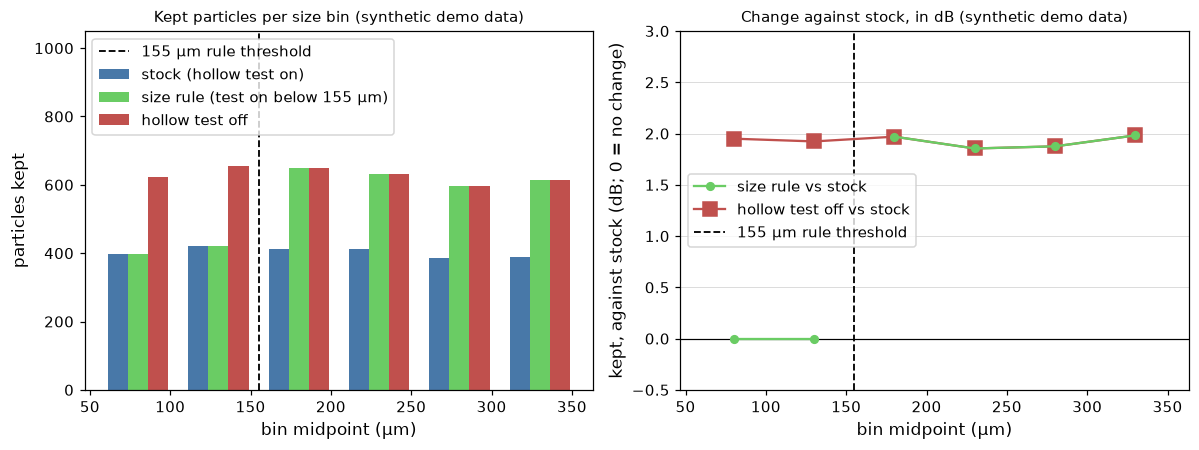

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 4.2))

width = (edges[1] - edges[0]) / 4.0
ax1.bar(centres - width, k_stock, width=width, label="stock (hollow test on)", color="#4878A8")
ax1.bar(centres, k_rule, width=width, label="size rule (test on below 155 µm)", color="#6ACC64")
ax1.bar(centres + width, k_off, width=width, label="hollow test off", color="#C0504D")
ax1.axvline(rule.threshold_um, color="black", linestyle="--", linewidth=1.2, label="155 µm rule threshold")
ax1.set_xlabel("bin midpoint (µm)")
ax1.set_ylabel("particles kept")
ax1.set_title("Kept particles per size bin (synthetic demo data)", fontsize=10)
ax1.set_ylim(0, 1050)
ax1.legend(fontsize=10, loc="upper left")

with np.errstate(divide="ignore", invalid="ignore"):
    r_rule = np.where(k_stock > 0, 10 * np.log10(k_rule / k_stock), np.nan)  # dB, never a linear ratio
    r_off = np.where(k_stock > 0, 10 * np.log10(k_off / k_stock), np.nan)
below = centres < rule.threshold_um  # the rule switches at 155 µm: two segments, no line across it
ax2.plot(np.where(below, centres, np.nan), np.where(below, r_rule, np.nan), marker="o", ms=5, color="#6ACC64", label="size rule vs stock", zorder=5)
ax2.plot(np.where(~below, centres, np.nan), np.where(~below, r_rule, np.nan), marker="o", ms=5, color="#6ACC64", zorder=5)
ax2.plot(centres, r_off, marker="s", ms=9, label="hollow test off vs stock", color="#C0504D")
ax2.axhline(0.0, color="black", linewidth=0.8)
ax2.axvline(rule.threshold_um, color="black", linestyle="--", linewidth=1.2, label="155 µm rule threshold")
ax2.set_xlim(ax1.get_xlim()); ax2.set_ylim(-0.5, 3.0)
ax2.set_yticks(np.arange(-0.5, 3.01, 0.5))
ax2.grid(axis="y", color="0.85", linewidth=0.6)
ax2.set_xlabel("bin midpoint (µm)")
ax2.set_ylabel("kept, against stock (dB; 0 = no change)")
ax2.set_title("Change against stock, in dB (synthetic demo data)", fontsize=10)
ax2.legend(fontsize=10, loc="center left")

fig.tight_layout()
fig.savefig(FIG_DIR / "11_kept_per_bin.png", dpi=120, metadata=PNG_META)
plt.show()

print("Read the right panel: the green line sits exactly on 0 dB below the")
print("threshold -- the rule changes nothing there, by construction -- and rises")
print("above it. The red line departs from 0 dB everywhere, including where the")
print("labels say the hollow test was RIGHT. That difference is the finding.")


*Figure 3. Left: particles kept per 50 µm size bin under stock, the size rule and the hollow test off (synthetic demo data). Right: each against stock in dB; the size rule is 0 dB below the 155 µm threshold (dashed) and about +2 dB above it, while switching the test off adds about 2 dB in every bin.*

In [10]:
below = centres < rule.threshold_um
agree = np.array_equal(k_rule[below], k_stock[below])
print("below the threshold, rule == stock exactly:", agree)

gain = k_rule[~below].sum() - k_stock[~below].sum()
print(f"above the threshold, the rule keeps {gain} more particles "
      f"({gain / max(k_stock[~below].sum(), 1):+.1%}) -- the labelled-real ones")

# What the blunt fix costs where the hollow test was RIGHT.
cost = k_off[below].sum() - k_stock[below].sum()
small = size_um < rule.threshold_um
artefacts = int((looks_hollow & ~is_really_real & small).sum())
print("")
print(f"below the threshold, turning the test OFF would keep {cost} more particles")
print(f"  of which {artefacts} are artefacts by construction -- counted as cloud")
print("  the size rule keeps none of them, which is the whole reason it exists")

below the threshold, rule == stock exactly: True
above the threshold, the rule keeps 891 more particles (+55.6%) -- the labelled-real ones

below the threshold, turning the test OFF would keep 459 more particles
  of which 383 are artefacts by construction -- counted as cloud
  the size rule keeps none of them, which is the whole reason it exists


## 4. How to do this on your own data

Nothing above needed a campaign file, and nothing above is specific to this instrument. The
method is four steps:

1. **Run once with stock settings** and keep the per-particle output.
2. **Look at the particles the hollow test rejected**, in size bins.
   `arrayprobe triage --decoded-dir <dir>` serves the images with the reject code beside each
   one; labels are written to a sidecar with your name, the queue and a timestamp, so a later
   re-pairing re-scores them rather than losing them.
3. **Put the labelled fraction in a table like section 1's.** If it is flat, you do not need a
   threshold. If it rises with size, the crossing point is your threshold.
4. **Re-run with the rule enabled** and compare, as section 3 does.

**Two things this notebook deliberately does not tell you.** It does not tell you that 155 µm is
your threshold -- it is one instrument's answer from 165 hand labels of stock rejects (480 labels in all). And it does not tell you the
hollow test is wrong; at small sizes it was right in every single labelled case. What transfers
is the method: the images decide, and they decide per size.

In [11]:
print("profiles you can name on a run:")
for name in ("stock-v3.5", "stock-v3.5-image-assisted"):
    p = PROFILES.get(name)
    print(f"  {name:<28} rej_hollow = {p.reject_thresholds.rej_hollow}")
print("\nand the size rule, which is opt-in and default-off:")
print(f"  HollowSizeRule(enabled=True, threshold_um=<your number>)")
print(f"  default (rule=None) is bit-identical to stock -- checked in section 2")

profiles you can name on a run:
  stock-v3.5                   rej_hollow = True
  stock-v3.5-image-assisted    rej_hollow = False

and the size rule, which is opt-in and default-off:
  HollowSizeRule(enabled=True, threshold_um=<your number>)
  default (rule=None) is bit-identical to stock -- checked in section 2
